# Домашняя работа 2.1. Двойной маятник

Два точечных груза соединены невесомыми жёсткими стержнями.
Трения нет. Приняты $m_1=m_2=1\,\mathrm{кг}$, $l_1=l_2=1\,\mathrm{м}$,
$g=9.81\,\mathrm{м/с^2}$. Углы отсчитываются от вертикали вниз;
состояние — $(\theta_1,\theta_2,\omega_1,\omega_2)$.

В основной части начальные углы равны $120^\circ$ и $-10^\circ$,
начальные угловые скорости нулевые. Меняется только первый угол.

## 1. Уравнения и методы

При выбранных единичных массах и длинах, обозначив
$\delta=\theta_1-\theta_2$, получаем систему для угловых ускорений:

$$
2\ddot\theta_1+\cos\delta\,\ddot\theta_2
=-2g\sin\theta_1-\omega_2^2\sin\delta,
$$

$$
\cos\delta\,\ddot\theta_1+\ddot\theta_2
=-g\sin\theta_2+\omega_1^2\sin\delta.
$$

Определитель $2-\cos^2\delta$ положителен.
Система решается на каждом шаге, затем применяется RK4.
Для проверки при малых углах также используется Адамс–Бэшфорт второго порядка (AB2),
первый шаг которого выполняется методом RK4.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from base64 import b64encode
from PIL import Image as PILImage
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25})
g = 9.81


def rhs(state):
    q1, q2, w1, w2 = np.moveaxis(state, -1, 0)
    delta = q1 - q2
    c, s = np.cos(delta), np.sin(delta)
    b1 = -2 * g * np.sin(q1) - w2**2 * s
    b2 = -g * np.sin(q2) + w1**2 * s
    a1 = (b1 - c * b2) / (2 - c**2)
    a2 = (2 * b2 - c * b1) / (2 - c**2)
    return np.stack([w1, w2, a1, a2], axis=-1)


def rk4_step(state, h):
    k1 = rhs(state)
    k2 = rhs(state + h * k1 / 2)
    k3 = rhs(state + h * k2 / 2)
    k4 = rhs(state + h * k3)
    return state + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def solve(initial, h, end, method="RK4"):
    n = round(end / h)
    t = np.arange(n + 1) * h
    states = np.empty((n + 1,) + initial.shape)
    states[0] = initial
    states[1] = rk4_step(initial, h)
    previous = rhs(initial)
    for i in range(1, n):
        if method == "RK4":
            states[i + 1] = rk4_step(states[i], h)
        else:
            current = rhs(states[i])
            states[i + 1] = states[i] + h * (3 * current - previous) / 2
            previous = current
    return t, states


def coordinates(states):
    q1, q2 = states[..., 0], states[..., 1]
    x1, y1 = np.sin(q1), -np.cos(q1)
    return x1, y1, x1 + np.sin(q2), y1 - np.cos(q2)


def energy(states):
    q1, q2, w1, w2 = np.moveaxis(states, -1, 0)
    return (w1**2 + w2**2 / 2 + w1 * w2 * np.cos(q1 - q2)
            + g * (2 * (1 - np.cos(q1)) + 1 - np.cos(q2)))

## 2. Проверка при малых отклонениях

Начальные углы $0.1$ и $0.05$ рад, скорости нулевые, время расчёта 20 с.
Таблица показывает максимальное относительное изменение полной энергии
для трёх шагов. Графики построены на самом мелком шаге $0.005\,\mathrm{с}$.
Нуль потенциальной энергии соответствует нижнему положению равновесия.

Метод     h, с        max |E(t) - E(0)| / E(0)
RK4       0.02        6.249e-06
RK4       0.01        1.956e-07
RK4       0.005       6.123e-09
AB2       0.02        1.989e-02
AB2       0.01        2.354e-03
AB2       0.005       2.916e-04


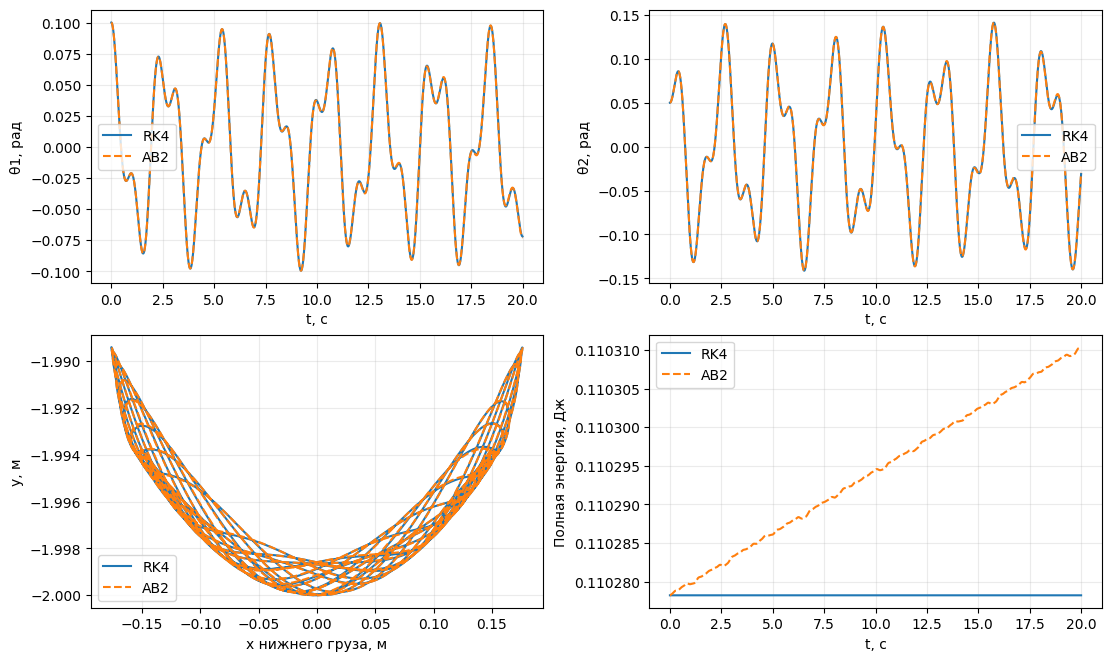

In [2]:
small_initial = np.array([0.1, 0.05, 0.0, 0.0])
small_runs = {}
print("Метод     h, с        max |E(t) - E(0)| / E(0)")
for method in ["RK4", "AB2"]:
    for h in [0.02, 0.01, 0.005]:
        t, states = solve(small_initial, h, 20, method)
        e = energy(states)
        print(f"{method:<10}{h:<12g}{np.max(np.abs(e - e[0])) / e[0]:.3e}")
        if h == 0.005:
            small_runs[method] = (t, states)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained")
for method, style in [("RK4", "-"), ("AB2", "--")]:
    t, states = small_runs[method]
    for j in range(2):
        axes[0, j].plot(t, states[:, j], style, label=method)
        axes[0, j].set(xlabel="t, с", ylabel=f"θ{j+1}, рад")
    x1, y1, x2, y2 = coordinates(states)
    axes[1, 0].plot(x2, y2, style, label=method)
    axes[1, 1].plot(t, energy(states), style, label=method)
axes[1, 0].set(xlabel="x нижнего груза, м", ylabel="y, м")
axes[1, 0].ticklabel_format(axis="y", useOffset=False)
axes[1, 1].set(xlabel="t, с", ylabel="Полная энергия, Дж")
for ax in axes.flat:
    ax.legend()
plt.show()

## 3. Большие углы и мера расхождения

К первому начальному углу добавляются $\varepsilon=10^{-2},10^{-3},10^{-4}$ рад.
Каждый запуск повторяется на пяти шагах от 0.01 до 0.000625 с до времени 30 с.
Начальное состояние при изменении шага не меняется.

Для сравнения состояний используется безразмерное расстояние

$$
D(A,B)=\sqrt{(\Delta\theta_1)^2+(\Delta\theta_2)^2+
\tau_0^2\big[(\Delta\omega_1)^2+(\Delta\omega_2)^2\big]},
\qquad \tau_0=\sqrt{l_1/g}.
$$

Разности углов приводятся к интервалу $[-\pi,\pi]$ через
$\operatorname{atan2}(\sin\Delta\theta,\cos\Delta\theta)$,
чтобы поворот на $2\pi$ не считался отличием положения.
Сами углы в уравнениях не обрезаются.

h, с       max относительного изменения энергии за 30 с
0.01        7.557e-05
0.005       2.849e-06
0.0025      7.404e-08
0.00125     3.949e-09
0.000625    2.630e-10


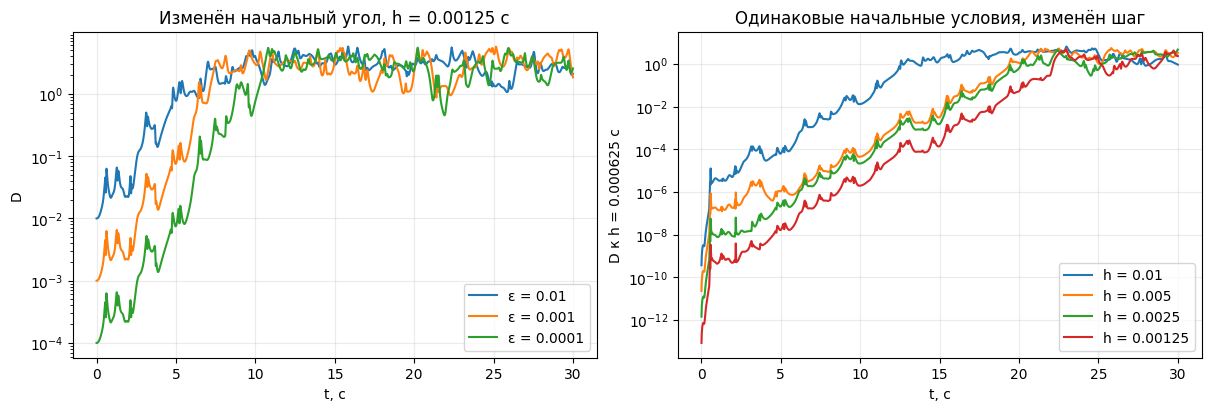

In [3]:
def distance(a, b):
    delta = (a - b).copy()
    delta[..., :2] = np.arctan2(np.sin(delta[..., :2]), np.cos(delta[..., :2]))
    delta[..., 2:] *= np.sqrt(1 / g)
    return np.linalg.norm(delta, axis=-1)


epsilons = np.array([0, 1e-2, 1e-3, 1e-4])
initial = np.tile([np.radians(120), np.radians(-10), 0, 0], (4, 1))
initial[:, 0] += epsilons
steps = [0.01, 0.005, 0.0025, 0.00125, 0.000625]
runs = {}
energy_errors = {}
for h in steps:
    time, values = solve(initial, h, 30)
    e = energy(values)
    energy_errors[h] = np.max(np.abs(e - e[0]) / e[0])
    runs[h] = values[::round(0.01 / h)]
t = np.arange(3001) * 0.01
reference = runs[0.000625]
main_h = 0.00125
main = runs[main_h]

print("h, с       max относительного изменения энергии за 30 с")
for h in steps:
    print(f"{h:<12g}{energy_errors[h]:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for j in range(1, 4):
    axes[0].semilogy(t, distance(main[:, j], main[:, 0]), label=f"ε = {epsilons[j]:g}")
for h in steps[:-1]:
    axes[1].semilogy(t[1:], distance(runs[h][:, 0], reference[:, 0])[1:], label=f"h = {h:g}")
axes[0].set(title="Изменён начальный угол, h = 0.00125 с", xlabel="t, с", ylabel="D")
axes[1].set(title="Одинаковые начальные условия, изменён шаг", xlabel="t, с", ylabel="D к h = 0.000625 с")
for ax in axes:
    ax.legend()
plt.show()

## 4. Интервал достоверного сравнения

Самый мелкий расчёт не считается точным решением. Обозначим через $Y_h$
решение с шагом $h$, через $Y_r$ — расчёт с шагом 0.000625 с.
Для каждого начального состояния оценивается расхождение

$$
e_h(t)=D(Y_h,Y_r)+D(Y_{0.00125},Y_r).
$$

Второе слагаемое учитывает оставшуюся неопределённость опорного расчёта по двум
самым мелким шагам. Для пары возмущённого и исходного решений берётся
$B_h=e_h^{(\varepsilon)}+e_h^{(0)}$.
Расхождение из-за начальных условий обозначено $S_h=D(Y_h^{(\varepsilon)},Y_h^{(0)})$.

Принимается практический критерий $B_h\leq0.1S_h$ и $B_h\leq0.01$:
различие при изменении шага должно быть как минимум в десять раз меньше изучаемого
эффекта и мало в абсолютном выражении.
В таблице указан последний момент перед первым нарушением критерия в общих узлах
с интервалом 0.01 с.

Вертикальные пунктирные линии отмечают границы для шага 0.00125 с.
Чёрная штриховая кривая показывает величину $10B_h$ для этого шага.

h, с       ε, рад       Конец проверенного интервала, с
0.01        0.01         8.07
0.01        0.001        7.43
0.01        0.0001       2.16
0.005       0.01         11.33
0.005       0.001        9.02
0.005       0.0001       14.46
0.0025      0.01         12.57
0.0025      0.001        12.00
0.0025      0.0001       14.89
0.00125     0.01         14.10
0.00125     0.001        16.35
0.00125     0.0001       16.19


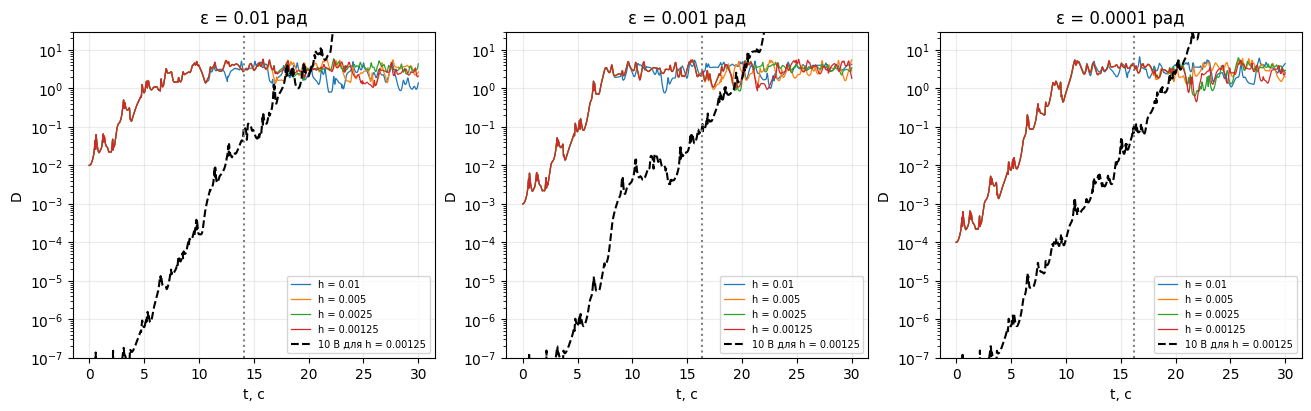

In [4]:
reference_change = distance(runs[0.00125], reference)
trust_times = {}
print("h, с       ε, рад       Конец проверенного интервала, с")
for h in steps[:-1]:
    errors = distance(runs[h], reference) + reference_change
    for j in range(1, 4):
        separation = distance(runs[h][:, j], runs[h][:, 0])
        budget = errors[:, 0] + errors[:, j]
        bad = np.flatnonzero((budget > 0.1 * separation) | (budget > 0.01))
        last = len(t) - 1 if len(bad) == 0 else max(0, bad[0] - 1)
        trust_times[h, j] = t[last]
        print(f"{h:<12g}{epsilons[j]:<13g}{t[last]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for j, ax in enumerate(axes, start=1):
    for h in steps[:-1]:
        separation = distance(runs[h][:, j], runs[h][:, 0])
        ax.semilogy(t, separation, label=f"h = {h:g}", linewidth=0.9)
    errors = distance(main, reference) + reference_change
    budget = errors[:, 0] + errors[:, j]
    ax.semilogy(t[1:], 10 * budget[1:], "k--", label="10 B для h = 0.00125")
    ax.axvline(trust_times[main_h, j], color="gray", linestyle=":")
    ax.set(title=f"ε = {epsilons[j]:g} рад", xlabel="t, с", ylabel="D", ylim=(1e-7, 30))
    ax.legend(fontsize=7)
plt.show()

## 5. Движение одного маятника

Анимация охватывает 12 с, что меньше найденного интервала достоверности.
Используется шаг 0.00125 с. Слева показаны стержни и след нижнего груза за последние
2 с, справа — оба угла; вертикальная линия отмечает текущий момент.
Кадры берутся из узлов численного решения через 0.05 с.


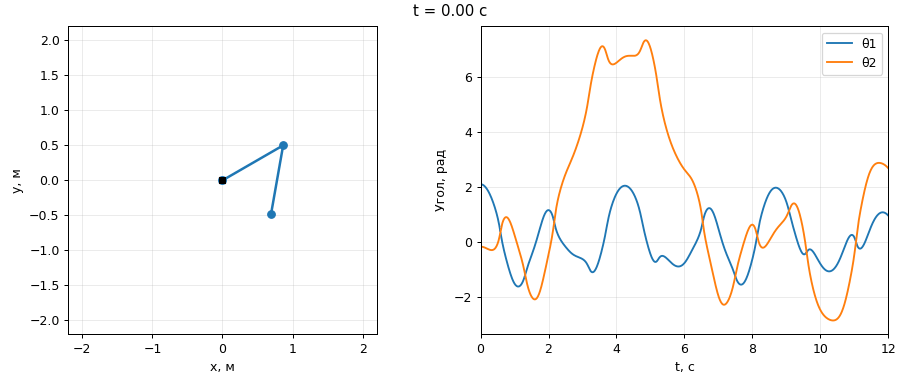

In [5]:
def show_animation(fig, update, frame_count):
    frames = []
    for i in range(frame_count):
        update(i)
        fig.canvas.draw()
        frames.append(PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB"))
    buffer = BytesIO()
    frames[0].save(buffer, format="GIF", save_all=True, append_images=frames[1:],
                   duration=50, loop=0)
    plt.close(fig)
    data = b64encode(buffer.getvalue()).decode("ascii")
    display(HTML(f'<img alt="Двойной маятник" src="data:image/gif;base64,{data}">'))


animation_time = np.arange(241) * 0.05
one = main[:1201:5, 0]
x1, y1, x2, y2 = coordinates(one)
fig_one, (ax_motion, ax_angles) = plt.subplots(1, 2, figsize=(10, 4.2), dpi=90,
                                             layout="constrained")
rod, = ax_motion.plot([], [], "o-", color="tab:blue", linewidth=2, markersize=6)
trail, = ax_motion.plot([], [], color="tab:orange", linewidth=0.9)
ax_motion.plot(0, 0, "ks", markersize=5)
ax_motion.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal", xlabel="x, м", ylabel="y, м")
for j in range(2):
    ax_angles.plot(t[:1201], main[:1201, 0, j], label=f"θ{j+1}")
cursor = ax_angles.axvline(0, color="black", linestyle="--")
ax_angles.set(xlim=(0, 12), xlabel="t, с", ylabel="Угол, рад")
ax_angles.legend()
title_one = fig_one.suptitle("")


def update_one(i):
    rod.set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
    start = max(0, i - 40)
    trail.set_data(x2[start:i + 1], y2[start:i + 1])
    cursor.set_xdata([animation_time[i], animation_time[i]])
    title_one.set_text(f"t = {animation_time[i]:.2f} с")


show_animation(fig_one, update_one, len(animation_time))

## 6. Ансамбль из десяти маятников

Начальный первый угол отличается от $120^\circ$ на $j\cdot10^{-4}$ рад,
где $j=0,1,\ldots,9$. Остальные начальные данные совпадают.
Каждый маятник рассчитан на шагах 0.00125 и 0.000625 с.
Перед анимацией проверяется, что сумма расхождений пары при уменьшении шага
не превышает 10% расстояния между ними и исходным маятником и остаётся меньше 0.01.

Максимальное расхождение одного маятника при уменьшении шага: 9.330e-04



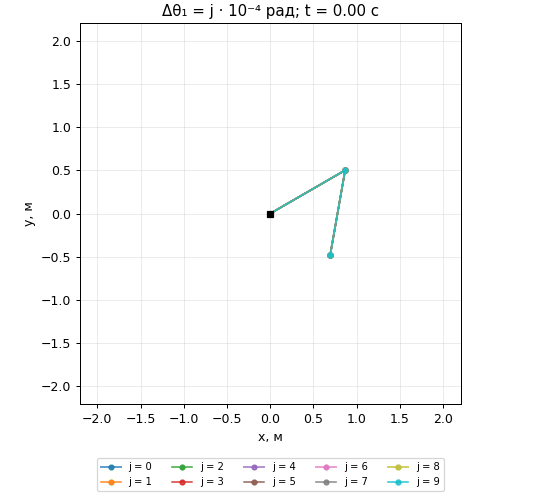

In [6]:
ensemble_eps = np.arange(10) * 1e-4
ensemble_initial = np.tile(initial[0], (10, 1))
ensemble_initial[:, 0] += ensemble_eps
te, ensemble = solve(ensemble_initial, 0.00125, 12)
_, ensemble_ref = solve(ensemble_initial, 0.000625, 12)
ensemble_error = distance(ensemble, ensemble_ref[::2])
for j in range(1, 10):
    sep = distance(ensemble[:, j], ensemble[:, 0])
    budget = ensemble_error[:, 0] + ensemble_error[:, j]
    assert np.all(budget <= 0.1 * sep)
    assert np.all(budget <= 0.01)
print(f"Максимальное расхождение одного маятника при уменьшении шага: {ensemble_error.max():.3e}")

ensemble_frames = ensemble[::40]
ex1, ey1, ex2, ey2 = coordinates(ensemble_frames)
fig_ensemble, ax = plt.subplots(figsize=(6, 5.5), dpi=90, layout="constrained")
colors = plt.cm.tab10(np.arange(10))
rods = []
for j, color in enumerate(colors):
    line, = ax.plot([], [], "o-", color=color, linewidth=1.3, markersize=4,
                    alpha=0.85, label=f"j = {j}")
    rods.append(line)
ax.plot(0, 0, "ks", markersize=5)
ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal", xlabel="x, м", ylabel="y, м")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=8)
title_ensemble = ax.set_title("")


def update_ensemble(i):
    for j, rod in enumerate(rods):
        rod.set_data([0, ex1[i, j], ex2[i, j]], [0, ey1[i, j], ey2[i, j]])
    title_ensemble.set_text(f"Δθ₁ = j · 10⁻⁴ рад; t = {animation_time[i]:.2f} с")


show_animation(fig_ensemble, update_ensemble, len(animation_time))

## Выводы

При больших начальных углах небольшое изменение первого угла приводит к заметному
расхождению движений. Рост расстояния немонотонный: участки сближения чередуются
с быстрым расхождением. Поэтому одной картинки расходящихся маятников недостаточно
для проверки точности или определения показателя Ляпунова.

При шаге 0.00125 с выбранный критерий выполняется от $t=0$ приблизительно до
14.10 с для возмущения $10^{-2}$ рад, 16.35 с для $10^{-3}$ рад и 16.19 с
для $10^{-4}$ рад. Общий интервал для всех трёх сравнений — до 14.10 с.
При шаге 0.01 с эти границы короче: 8.07, 7.43 и 2.16 с соответственно.
После указанных границ данный расчёт уже не подтверждает количественную величину
расхождения: нужно уменьшать шаг и повторять сравнение.

Обе анимации ограничены 12 с. Для ансамбля максимальное различие состояний
при уменьшении шага составило $9.33\cdot10^{-4}$; для каждой пары с исходным
маятником оно мало относительно эффекта возмущения на всём этом интервале.
Относительное изменение энергии для шага 0.00125 с не превышает
$4.0\cdot10^{-9}$ за 30 с. Хорошее сохранение энергии само по себе не означает,
что фазы и положения маятников остаются точными на всём интервале.